# 06 · Item text preparation (input to Model 1's semantic layer)

### What this notebook does
1. Builds one clean, structured **item text** per product from metadata: title, brand, category path, features,
   description, price band.
2. (Optional, `include_review_text`) Streams the review file and keeps **only reviews from training interactions** of
   the final subset. Adds up to 3 helpful review snippets per item → `item_text_with_reviews`.
3. Saves **interaction side information** (`verified_purchase`, `helpful_vote`) for the optional RecPO module.
4. Runs text quality checks (empty, very short, duplicate texts) and prints examples.
5. Adds empty `llm_profile` columns: the slot for LLM-generated profiles (Profile-then-Embedding) in the Model 1 stage.

### Why
- Model 1 encodes item text with BLaIR or a sentence encoder. A consistent template with labelled fields gives the
  encoder (and later the LLM) clean, comparable input for every item.
- The report's safeguard: **"fit semantic preprocessing only on training information"**. Review text from a user's
  validation or test interaction would describe the very purchase we try to predict, so it is excluded.

**Inputs:** `processed/items.parquet`, `processed/interactions.parquet`, `processed/user_map.parquet`,
`processed/item_map.parquet` · **Outputs:** `processed/item_text.parquet`, `processed/train_reviews.parquet`,
`processed/interaction_side_info.parquet`

In [2]:
# ---------------- Shared setup (identical in every notebook) ----------------
# All notebooks read and write inside one project folder (BASE).
# Colab: BASE lives in your Google Drive so outputs survive runtime restarts.
# Local Jupyter: BASE is ./298A_recsys next to the notebooks.
# Set the environment variable RECSYS_BASE to use any other folder.
import os, sys, json, re, time, hashlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', category=FutureWarning)

IN_COLAB = 'google.colab' in sys.modules
if os.environ.get('RECSYS_BASE'):
    BASE = Path(os.environ['RECSYS_BASE'])
elif IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/298A/04_Data/NewDataRunFiles')
else:
    BASE = Path('./298A_recsys').resolve()

RAW, INTERIM, PROCESSED = BASE / 'raw', BASE / 'interim', BASE / 'processed'
REPORTS, FIGS = BASE / 'reports', BASE / 'reports' / 'figures'
# Large downloads go to fast local disk in Colab (not Drive); re-downloaded if the runtime resets.
DOWNLOADS = Path(os.environ.get('RECSYS_DOWNLOAD_DIR', '/content/downloads' if IN_COLAB else str(BASE / 'downloads')))
for d in [RAW, INTERIM, PROCESSED, REPORTS, FIGS, DOWNLOADS]:
    d.mkdir(parents=True, exist_ok=True)

# Plot style: one hue per single-series chart, light recessive grid, no chart junk.
PRIMARY, ACCENT, MUTED = '#2a78d6', '#eb6834', '#8a8984'
plt.rcParams.update({
    'figure.figsize': (8, 4), 'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6, 'axes.edgecolor': '#b5b4ae',
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.labelsize': 9, 'xtick.labelsize': 8,
    'ytick.labelsize': 8, 'axes.prop_cycle': matplotlib.cycler(color=[PRIMARY, ACCENT, '#1baf7a', '#eda100']),
})

def save_json(obj, path):
    Path(path).write_text(json.dumps(obj, indent=2, default=str))

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGS / f'{name}.png', bbox_inches='tight')
    plt.show()

def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(chunk), b''):
            h.update(block)
    return h.hexdigest()

def load_config():
    cfg_path = BASE / 'config.json'
    if not cfg_path.exists():
        raise FileNotFoundError('config.json not found - run 01_data_acquisition.ipynb first.')
    return json.loads(cfg_path.read_text())

print('Project folder:', BASE)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/298A/04_Data/NewDataRunFiles


In [3]:
import gzip
CFG = load_config()
TXT = CFG['text']
items = pd.read_parquet(PROCESSED / 'items.parquet')
inter = pd.read_parquet(PROCESSED / 'interactions.parquet')
user_map = pd.read_parquet(PROCESSED / 'user_map.parquet')
item_map = pd.read_parquet(PROCESSED / 'item_map.parquet')
N_ITEMS = len(items)
print(f'{N_ITEMS:,} items | {len(inter):,} interactions')

25,903 items | 501,399 interactions


## 1. Structured metadata text
Template (empty fields are skipped):
```
Title: … | Brand: … | Category: Skin Care > Face > Moisturizers | Features: … | Description: … | Price: $10-25
```
Price is bucketed into bands instead of exact values (exact prices add noise to text embeddings). The full text is
capped at `max_item_text_words` words, roughly what a 512-token encoder can take.

In [4]:
def price_band(p):
    if pd.isna(p): return ''
    for hi, label in [(10, 'under $10'), (25, '$10-25'), (50, '$25-50'), (100, '$50-100')]:
        if p < hi: return label
    return 'over $100'

def truncate_words(s, n):
    w = str(s).split()
    return ' '.join(w) if len(w) <= n else ' '.join(w[:n]) + ' ...'

def cat_display(path):
    parts = [p for p in str(path or '').split(' > ') if p]
    return ' > '.join(parts[1:] if len(parts) > 1 else parts)   # drop the constant root "Beauty & Personal Care"

def build_meta_text(r):
    fields = [('Title', r.title), ('Brand', r.brand), ('Category', cat_display(r.cat_path)),
              ('Features', truncate_words(r.features_text or '', 80)),
              ('Description', truncate_words(r.description_text or '', 120)),
              ('Price', price_band(r.price_num))]
    text = ' | '.join(f'{k}: {v}' for k, v in fields if isinstance(v, str) and v.strip())
    return truncate_words(text, TXT['max_item_text_words'])

items['item_text'] = items.apply(build_meta_text, axis=1)
for t in items.item_text.head(3):
    print(t, '\n')

Title: SmartLab Toys Go Natural Deluxe Lip Balm Lab with 20 Recipes, Tips and Techniques. STEM Science Lab | Brand: SmartLab | Category: Skin Care > Lip Care > Balms & Moisturizers | Features: All-natural ingredients, hands-on learning fun: This deluxe lip balm lab provides tools and ingredients to make all-natural, colorful, flavored lip balms at home--just add vegetable oil from the pantry and your choice of add-ins ; Exclusive new travel pods: Exclusively designed travel pods can be attached with a carabiner to backpack, zipper pull, keychain, or purse; slim design slips into a jeans pocket but still can accommodate two different colors or flavors ; Proprietary mix-and-melt silcone mold: Allows for one-step ... | Description: Go Natural Deluxe Lip Balm Lab builds on the success of the best-selling All-Natural Lip Balm Boutique kit by including the main ingredients needed to make custom lip balms, including flavor and color. Additional exclusive components include a mix-and-melt sili

## 2. Review text from training interactions only (optional)
The review file is several GB, so it is streamed line by line and only rows matching a **training** interaction of
the final subset are kept. Matching uses `(user_id, parent_asin, timestamp)` so each review is tied to exactly one
interaction in our data.

Set `include_review_text = False` in `config.json` to skip this (Model 1 then uses metadata text only).

In [5]:
inter_k = (inter.merge(user_map, on='user_idx').merge(item_map, on='item_idx'))
key_split = dict(zip(zip(inter_k.user_id, inter_k.parent_asin, inter_k.timestamp), inter_k.split))
pair_split = {}
for (u, a, t), s in key_split.items():
    pair_split[(u, a)] = (t, s)

reviews = pd.DataFrame(columns=['user_id', 'parent_asin', 'timestamp', 'rating', 'title', 'text',
                                'helpful_vote', 'verified_purchase', 'split', 'match'])
if CFG['include_review_text']:
    def download(url, dest):
        import requests
        dest = Path(dest)
        if dest.exists() and dest.stat().st_size > 0:
            print('Already present:', dest); return dest
        tmp = dest.with_suffix(dest.suffix + '.part')
        print('Downloading', url, '(large file, this can take a while)')
        with requests.get(url, stream=True, timeout=60) as r:
            r.raise_for_status()
            with open(tmp, 'wb') as f:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    f.write(chunk)
        tmp.rename(dest); return dest

    reviews_gz = download(CFG['urls']['reviews'], DOWNLOADS / 'Beauty_and_Personal_Care.reviews.jsonl.gz')
    rows, n_lines = [], 0
    with gzip.open(reviews_gz, 'rt', encoding='utf-8') as f:
        for line in f:
            n_lines += 1
            if n_lines % 2_000_000 == 0:
                print(f'  scanned {n_lines:,} reviews, matched {len(rows):,}')
            rec = json.loads(line)
            u, a = rec.get('user_id'), rec.get('parent_asin')
            hit = pair_split.get((u, a))
            if hit is None:
                continue
            ts = rec.get('timestamp', rec.get('sort_timestamp'))
            exact = (u, a, ts) in key_split
            rows.append({'user_id': u, 'parent_asin': a, 'timestamp': ts if exact else hit[0],
                         'rating': rec.get('rating'), 'title': rec.get('title') or '', 'text': rec.get('text') or '',
                         'helpful_vote': rec.get('helpful_vote', rec.get('helpful_votes', 0)) or 0,
                         'verified_purchase': bool(rec.get('verified_purchase', False)),
                         'split': key_split[(u, a, ts)] if exact else hit[1],
                         'match': 'exact' if exact else 'user_item'})
    reviews = pd.DataFrame(rows)
    # A user can review the same product twice; keep the review whose timestamp matches our interaction.
    reviews = (reviews.sort_values(['match']).drop_duplicates(['user_id', 'parent_asin'], keep='first'))
    print(f'Scanned {n_lines:,} reviews; matched {len(reviews):,} of {len(inter):,} interactions '
          f'({len(reviews) / len(inter):.1%}); exact timestamp matches: {(reviews.match == "exact").mean():.1%}')
    display(reviews.split.value_counts())

  scanned 2,000,000 reviews, matched 136,628
  scanned 4,000,000 reviews, matched 227,007
  scanned 6,000,000 reviews, matched 314,356
  scanned 8,000,000 reviews, matched 359,270
  scanned 10,000,000 reviews, matched 407,380
  scanned 12,000,000 reviews, matched 434,357
  scanned 14,000,000 reviews, matched 467,966
  scanned 16,000,000 reviews, matched 485,276
  scanned 18,000,000 reviews, matched 503,737
  scanned 20,000,000 reviews, matched 507,502
  scanned 22,000,000 reviews, matched 509,272
Scanned 23,911,390 reviews; matched 501,399 of 501,399 interactions (100.0%); exact timestamp matches: 100.0%


,count
split,
train,389365
test,56017
val,56017


### 2a. Interaction side information (no text)
`verified_purchase` and `helpful_vote` per interaction, for the optional RecPO weighting. These are properties of the
interaction itself, not text about the target, so they are kept for all splits; models must only *use* them on
training interactions.

In [6]:
side = inter_k[['user_idx', 'item_idx', 'user_id', 'parent_asin', 'split']].merge(
    reviews[['user_id', 'parent_asin', 'verified_purchase', 'helpful_vote']], on=['user_id', 'parent_asin'], how='left')
side = side[['user_idx', 'item_idx', 'split', 'verified_purchase', 'helpful_vote']]
side.to_parquet(PROCESSED / 'interaction_side_info.parquet', index=False)
print('Side info coverage:', f'{side.verified_purchase.notna().mean():.1%}')

Side info coverage: 100.0%


### 2b. Review snippets per item (training reviews only)
Up to `n_review_snippets` reviews per item, preferring the most helpful, then the most recent; each truncated to
`review_snippet_words` words. Reviews shorter than 5 words ("Great!") carry little information and are skipped.

In [7]:
train_reviews = reviews[reviews.split == 'train'].copy()
if len(train_reviews):
    train_reviews['clean'] = (train_reviews.title.astype(str).str.strip() + '. ' + train_reviews.text.astype(str)) \
        .str.replace(r'<[^>]+>', ' ', regex=True).str.replace(r'\s+', ' ', regex=True).str.strip(' .')
    train_reviews = train_reviews[train_reviews.clean.str.split().str.len() >= 5]
    train_reviews = train_reviews.merge(item_map, on='parent_asin')
    train_reviews = train_reviews.sort_values(['item_idx', 'helpful_vote', 'timestamp'], ascending=[True, False, False])
    top = train_reviews.groupby('item_idx').head(TXT['n_review_snippets'])
    snippets = top.groupby('item_idx').clean.apply(
        lambda s: ' || '.join(truncate_words(x, TXT['review_snippet_words']) for x in s))
    items['review_snippets'] = items.item_idx.map(snippets).fillna('')
    train_reviews.drop(columns=['clean']).to_parquet(PROCESSED / 'train_reviews.parquet', index=False)
else:
    items['review_snippets'] = ''
items['n_review_snippets'] = items.review_snippets.apply(lambda s: 0 if not s else s.count(' || ') + 1)
items['item_text_with_reviews'] = np.where(items.review_snippets != '',
                                           items.item_text + ' | Reviews: ' + items.review_snippets, items.item_text)
print(f'Items with at least one review snippet: {(items.n_review_snippets > 0).mean():.1%}')

Items with at least one review snippet: 99.8%


## 3. Quality checks

{
  "items": 25903,
  "empty_item_text": 0,
  "very_short_item_text_lt_8_words": 0,
  "items_sharing_identical_text": 236,
  "item_text_words": {
    "count": 25903.0,
    "mean": 131.7,
    "std": 64.0,
    "min": 11.0,
    "50%": 128.0,
    "90%": 238.0,
    "max": 257.0
  },
  "item_text_with_reviews_words": {
    "count": 25903.0,
    "mean": 279.8,
    "std": 76.4,
    "min": 18.0,
    "50%": 285.0,
    "90%": 387.0,
    "max": 444.0
  },
  "items_with_review_snippets_pct": 99.76
}


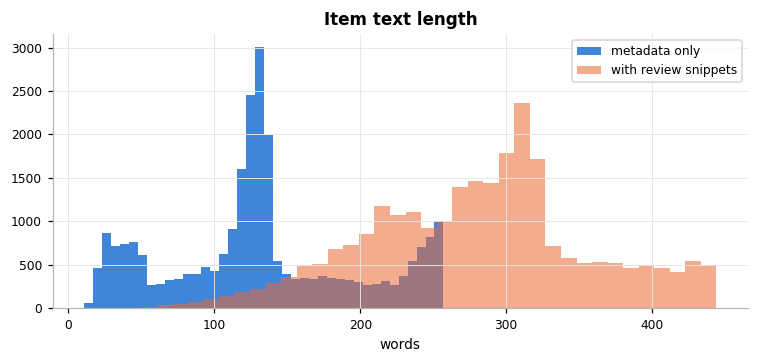

Example items with identical text (often colour/size variants listed separately):


,item_idx,parent_asin,item_text
4593,4594,B00D8G8KEG,Title: 1lb Hemp Oil (all natural) Glycerin Mel...
4595,4596,B00D8GIQ4U,Title: 1lb Hemp Oil (all natural) Glycerin Mel...
7394,7395,B0149KZX94,Title: 1lb Hemp Oil (all natural) Glycerin Mel...
25161,25162,B0C4TNSQ2R,"Title: 2 in 1 Electric Face Massager, 3D Rolle..."
17699,17700,B09DGJHGDT,"Title: 2 in 1 Electric Face Massager, 3D Rolle..."
8111,8112,B01EOQ2BWU,Title: Apricot Beauty & Healthcare Silicon Car...


In [8]:
items['text_words'] = items.item_text.str.split().str.len()
items['text_with_reviews_words'] = items.item_text_with_reviews.str.split().str.len()
dup_text = items.duplicated('item_text', keep=False)
quality = {
    'items': N_ITEMS,
    'empty_item_text': int((items.text_words == 0).sum()),
    'very_short_item_text_lt_8_words': int((items.text_words < 8).sum()),
    'items_sharing_identical_text': int(dup_text.sum()),
    'item_text_words': items.text_words.describe(percentiles=[.5, .9]).round(1).to_dict(),
    'item_text_with_reviews_words': items.text_with_reviews_words.describe(percentiles=[.5, .9]).round(1).to_dict(),
    'items_with_review_snippets_pct': round(100 * float((items.n_review_snippets > 0).mean()), 2),
}
print(json.dumps(quality, indent=2))
assert quality['empty_item_text'] == 0, 'every item must have text (titles were enforced in notebook 03)'

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(items.text_words, bins=40, color=PRIMARY, alpha=0.9, label='metadata only')
ax.hist(items.text_with_reviews_words, bins=40, color=ACCENT, alpha=0.55, label='with review snippets')
ax.set_title('Item text length'); ax.set_xlabel('words'); ax.legend(fontsize=8)
savefig('06_item_text_length')

if dup_text.any():
    print('Example items with identical text (often colour/size variants listed separately):')
    display(items.loc[dup_text, ['item_idx', 'parent_asin', 'item_text']].sort_values('item_text').head(6))

### Leakage check for review text

In [9]:
if len(train_reviews):
    tr_pairs = set(zip(inter_k.loc[inter_k.split == 'train', 'user_id'], inter_k.loc[inter_k.split == 'train', 'parent_asin']))
    used_pairs = set(zip(train_reviews.user_id, train_reviews.parent_asin))
    assert used_pairs <= tr_pairs, 'review snippets must come only from training interactions'
    print('PASS: every review snippet comes from a training interaction')
quality['review_text_from_train_only'] = True
save_json(quality, REPORTS / 'item_text_quality.json')

PASS: every review snippet comes from a training interaction


## 4. Examples

In [10]:
for _, r in items.sample(3, random_state=CFG['seed']).iterrows():
    print(f'item_idx={r.item_idx}  ({r.text_with_reviews_words} words)')
    print(r.item_text_with_reviews[:900], '\n')

item_idx=13124  (250 words)
Title: Aadya Care Face Scrub (Pack of 2) | Brand: AADYA LIFE | Category: Skin Care > Face > Polishes & Scrubs > Scrubs | Features: Aadya Care Face Scrub is infused with natural herbs and essential oil which removes dead skin cells without reducing natural smoothness of skin. ; It is enriched with walnut shell fibers which gently exfoliates skin, unclogs skin pores and revives skin tone. ; Works on blackheads, removes dead skin and excess oil. ; Makes skin brighter and radiant. ; A Sulphate free and Paraben free product. No artificial color added. | Reviews: ♥️💖💓Cleans Oily Skins Effectively, but. Too Watery😣😣. [[VIDEOID:e9b0a36af4b1319ffa86adb544cbed3b]] I came across this by accident as I was looking for some exfoliating facial scrub to help get rid of my dull dead skins, and also remove the excess oils due to my very oily skin type. I had tried brands made in America & Korea, but this  

item_idx=22207  (383 words)
Title: Face Massager with Jade Roller Sil

## 5. Save
`llm_profile` and `llm_profile_model` are left empty here. In the Model 1 stage, an LLM writes a short grounded profile
per item (Profile-then-Embedding) into this column, after which embeddings are computed.

In [11]:
items['llm_profile'] = ''
items['llm_profile_model'] = ''
out_cols = ['item_idx', 'parent_asin', 'title', 'brand', 'cat_path', 'cat_l1', 'cat_l2', 'cat_l3', 'price_num',
            'item_text', 'review_snippets', 'n_review_snippets', 'item_text_with_reviews', 'text_words',
            'text_with_reviews_words', 'llm_profile', 'llm_profile_model']
item_text = items[out_cols].sort_values('item_idx').reset_index(drop=True)
assert item_text.item_idx.tolist() == list(range(1, N_ITEMS + 1))
item_text.to_parquet(PROCESSED / 'item_text.parquet', index=False)
print('Saved', PROCESSED / 'item_text.parquet')

Saved /content/drive/MyDrive/298A/04_Data/NewDataRunFiles/processed/item_text.parquet


**Next:** `07_freeze_and_sanity_check.ipynb`